# Notebook 05 — Data Visualisation


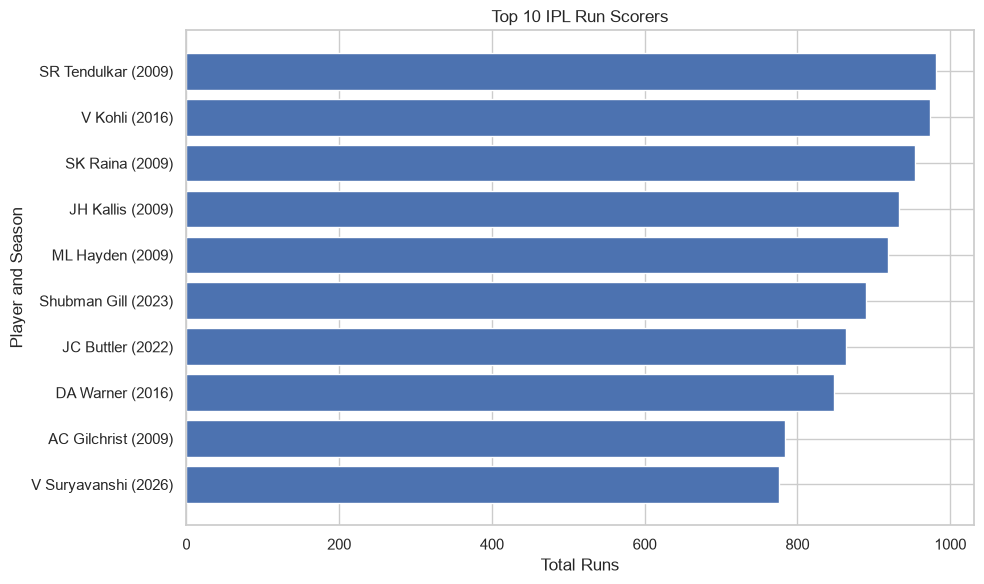

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

BASE_DIR = Path.cwd()
if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

PROCESSED_DIR = BASE_DIR / "data" / "processed"
df = pd.read_csv(PROCESSED_DIR / "IPL_Batting_Statistics_Cleaned.csv")
innings_df = pd.read_csv(PROCESSED_DIR / "IPL_Batting_Innings_Cleaned.csv")

BASE_DIR = Path.cwd()
if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent
FIGURE_DIR = BASE_DIR / "outputs" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

top_scorers = df.nlargest(10, "Runs")


plt.figure(figsize=(10, 6))
labels = top_scorers["Player"] + " (" + top_scorers["Season"].astype(str) + ")"
plt.barh(labels, top_scorers["Runs"])
plt.xlabel("Total Runs")
plt.ylabel("Player and Season")
plt.title("Top 10 IPL Run Scorers")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "top_10_run_scorers.png", dpi=300)
plt.show()


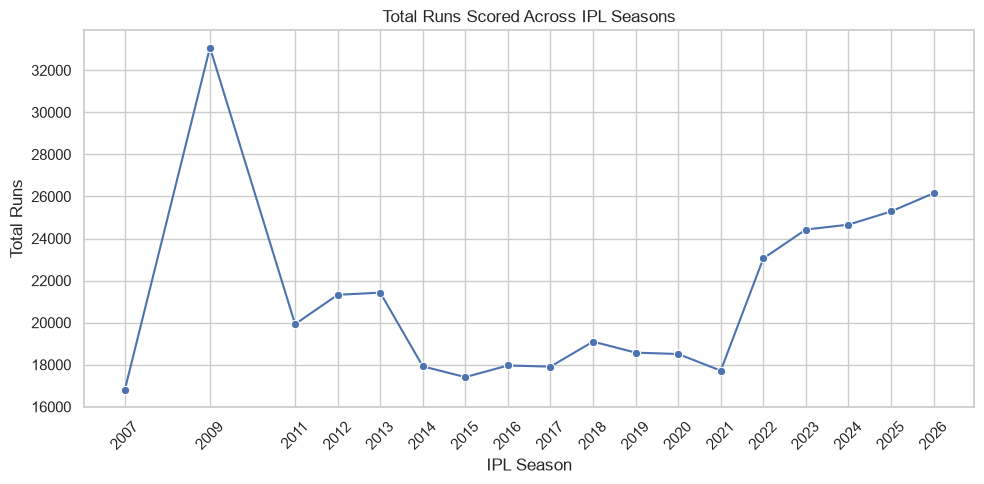

In [2]:
season_runs = df.groupby("Season")["Runs"].sum().reset_index()
plt.figure(figsize=(10, 5))
sns.lineplot(data=season_runs, x="Season", y="Runs", marker="o")
plt.title("Total Runs Scored Across IPL Seasons")
plt.xlabel("IPL Season")
plt.ylabel("Total Runs")
plt.xticks(season_runs["Season"], rotation=45)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "season_wise_runs.png", dpi=300)
plt.show()


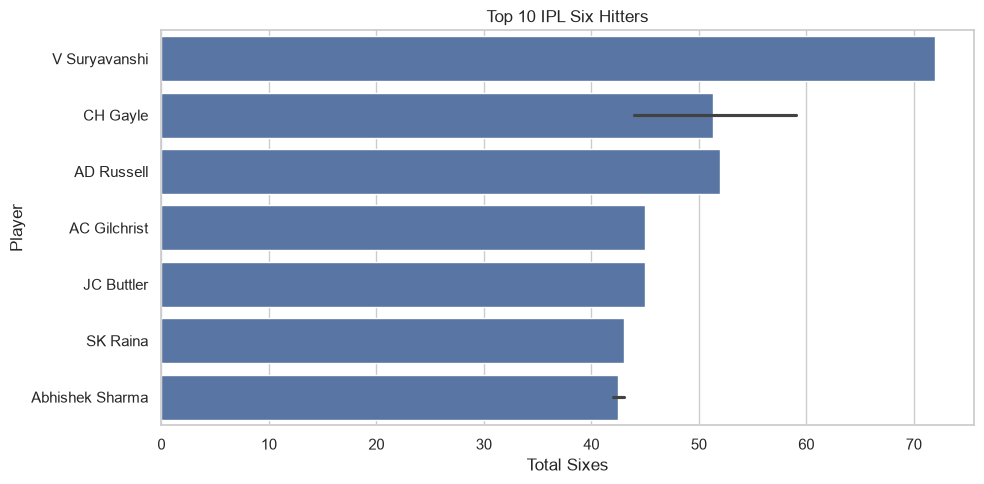

In [3]:
top_six_hitters = df.nlargest(10, "Sixes")
plt.figure(figsize=(10, 5))
sns.barplot(data=top_six_hitters, x="Sixes", y="Player")
plt.title("Top 10 IPL Six Hitters")
plt.xlabel("Total Sixes")
plt.ylabel("Player")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "top_10_six_hitters.png", dpi=300)
plt.show()


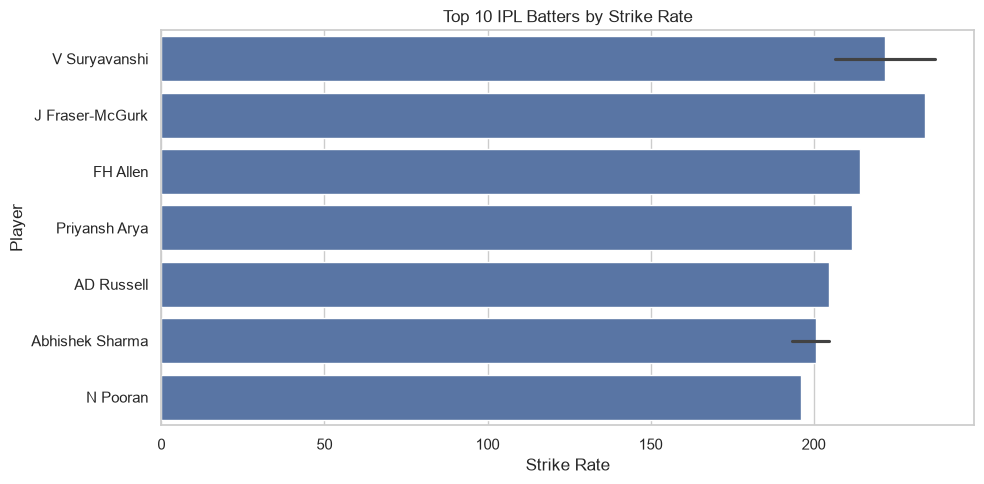

In [4]:
qualified_players = df[df["Balls_Faced"] >= 100]
top_strikers = qualified_players.nlargest(10, "Strike_Rate")
plt.figure(figsize=(10, 5))
sns.barplot(data=top_strikers, x="Strike_Rate", y="Player")
plt.title("Top 10 IPL Batters by Strike Rate")
plt.xlabel("Strike Rate")
plt.ylabel("Player")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "top_10_strike_rates.png", dpi=300)
plt.show()


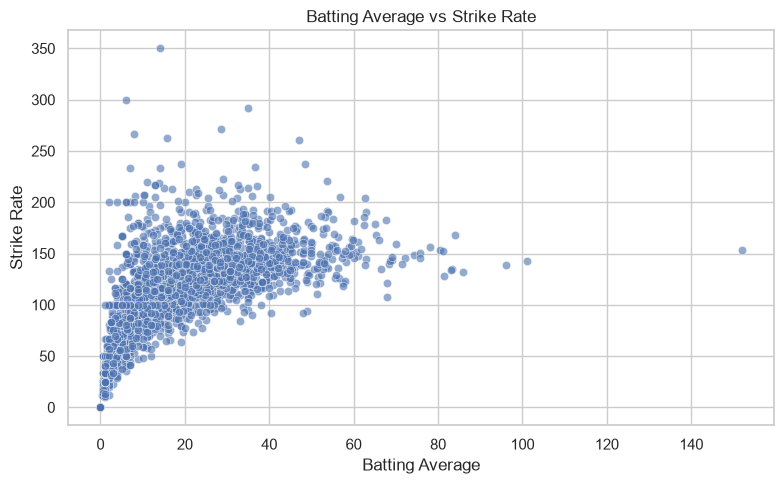

In [5]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Batting_Average", y="Strike_Rate", alpha=0.6)
plt.title("Batting Average vs Strike Rate")
plt.xlabel("Batting Average")
plt.ylabel("Strike Rate")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "average_vs_strike_rate.png", dpi=300)
plt.show()


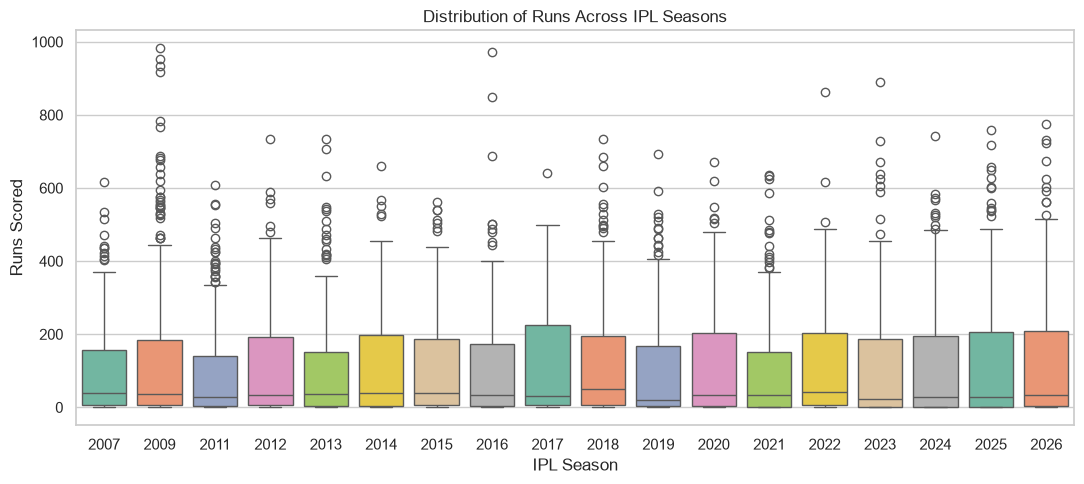

In [6]:
plt.figure(figsize=(11, 5))
sns.boxplot(
    data=df, x="Season", y="Runs", hue="Season",
    palette="Set2", dodge=False,
)
plt.title("Distribution of Runs Across IPL Seasons")
plt.xlabel("IPL Season")
plt.ylabel("Runs Scored")
plt.legend([], [], frameon=False)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "season_runs_boxplot.png", dpi=300)
plt.show()


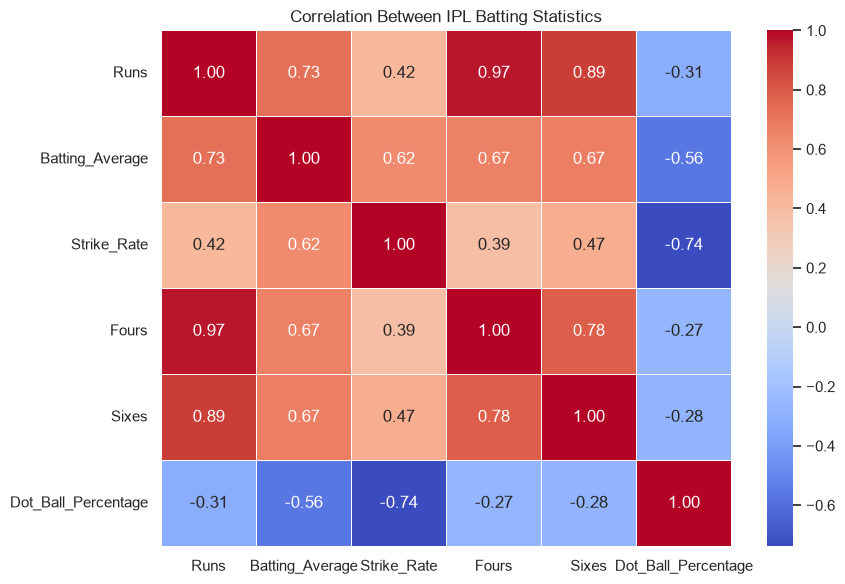

In [7]:
correlation = df[
    ["Runs", "Batting_Average", "Strike_Rate", "Fours", "Sixes", "Dot_Ball_Percentage"]
].corr()
plt.figure(figsize=(9, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Between IPL Batting Statistics")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "batting_correlation_heatmap.png", dpi=300)
plt.show()


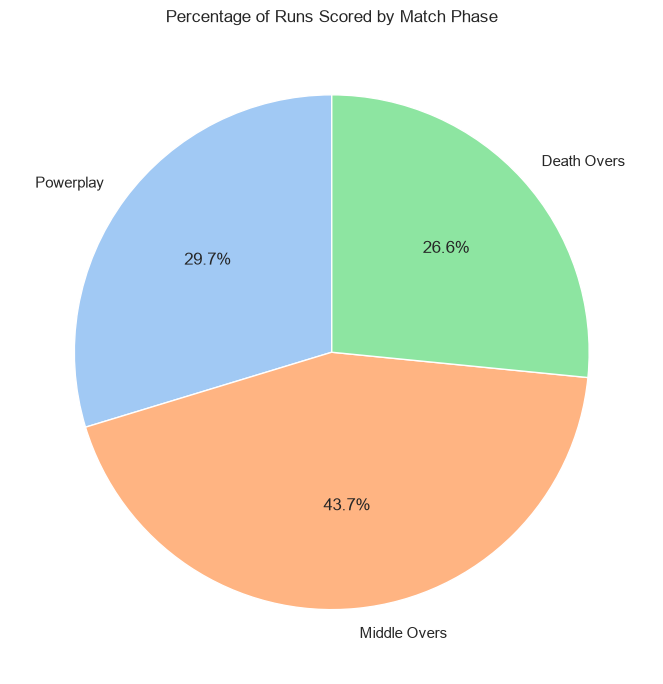

In [8]:
phase_runs = [
    df["Powerplay_Runs"].sum(),
    df["Middle_Overs_Runs"].sum(),
    df["Death_Overs_Runs"].sum(),
]
phases = ["Powerplay", "Middle Overs", "Death Overs"]
plt.figure(figsize=(7, 7))
plt.pie(
    phase_runs, labels=phases, autopct="%1.1f%%",
    startangle=90, colors=sns.color_palette("pastel"),
)
plt.title("Percentage of Runs Scored by Match Phase")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "phase_wise_runs_pie.png", dpi=300)
plt.show()


/var/folders/1t/73m1ypm128s5cxsv71l_ytp80000gn/T/ipykernel_1500/3450449351.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


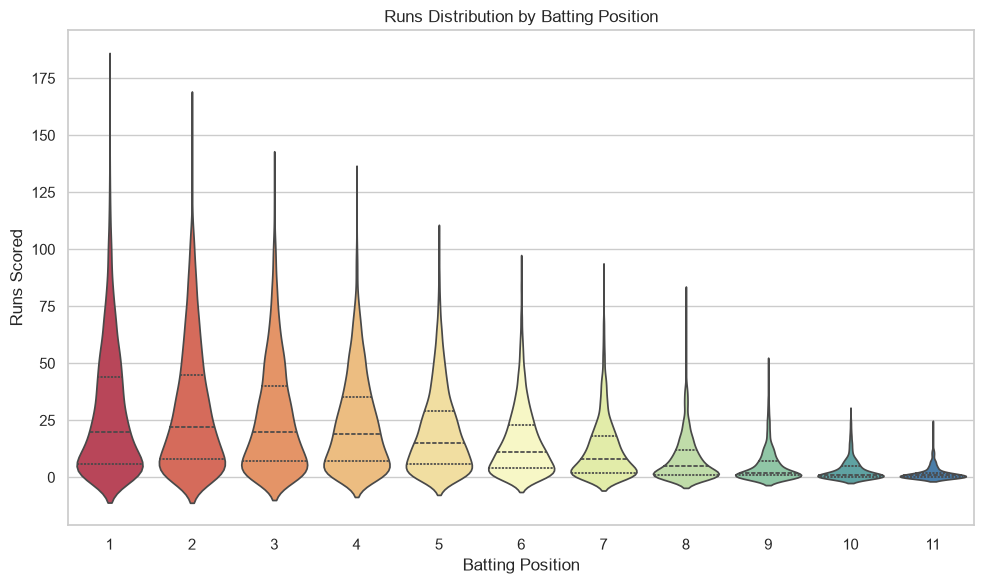

In [9]:
position_data = innings_df[innings_df["Batting_Position"].between(1, 11)]
plt.figure(figsize=(10, 6))
sns.violinplot(
    data=position_data, x="Batting_Position", y="Runs",
    palette="Spectral", inner="quartile",
)
plt.title("Runs Distribution by Batting Position")
plt.xlabel("Batting Position")
plt.ylabel("Runs Scored")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "batting_position_violin.png", dpi=300)
plt.show()


Dropdown(description='Choose Player:', index=540, options=('A Ashish Reddy', 'A Badoni', 'A Chandila', 'A Chop…

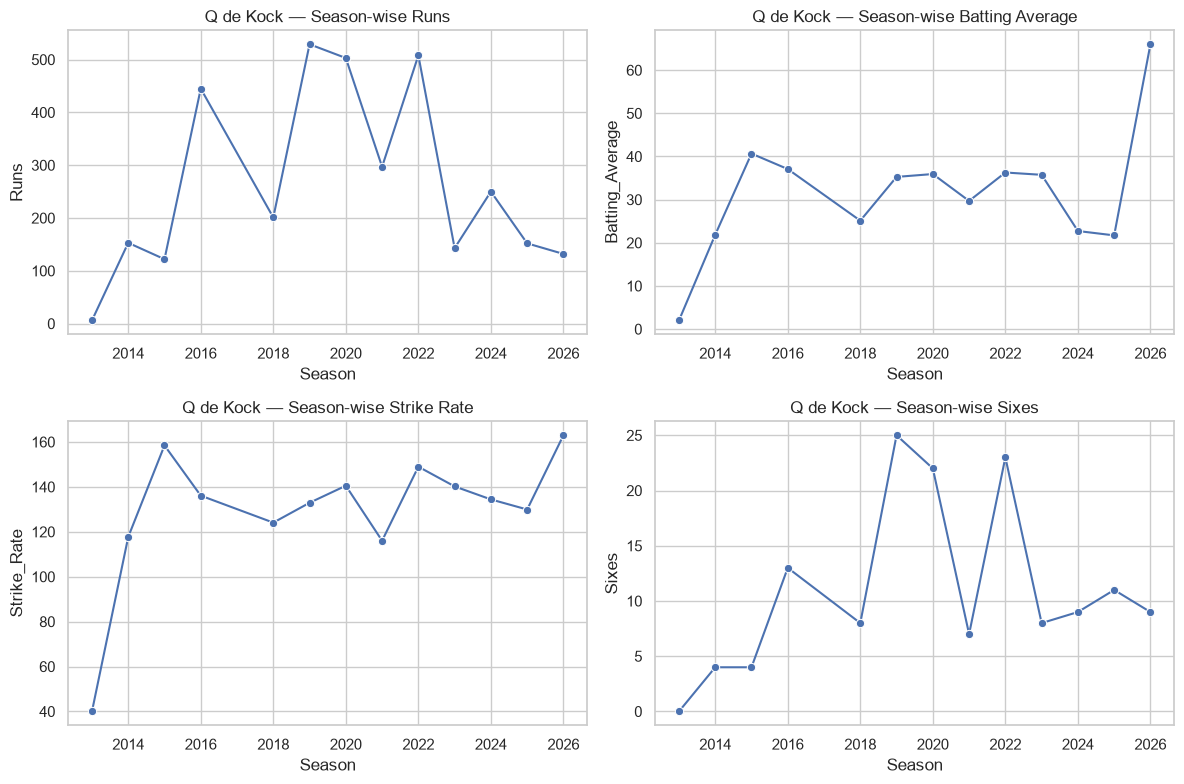

In [10]:
import ipywidgets as widgets
from IPython.display import display, clear_output

player_list = sorted(df["Player"].dropna().unique())

def plot_player_season_stats(player):
    clear_output(wait=True)
    display(player_filter)
    player_df = df[df["Player"] == player].sort_values("Season")
    if player_df.empty:
        print("No records for", player)
        return

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    charts = [
        ("Runs", "Season-wise Runs"),
        ("Batting_Average", "Season-wise Batting Average"),
        ("Strike_Rate", "Season-wise Strike Rate"),
        ("Sixes", "Season-wise Sixes"),
    ]
    for ax, (col, title) in zip(axes.flat, charts):
        sns.lineplot(data=player_df, x="Season", y=col, marker="o", ax=ax)
        ax.set_title(f"{player} — {title}")
        ax.set_xlabel("Season")
    plt.tight_layout()
    plt.show()

player_filter = widgets.Dropdown(
    options=player_list,
    description="Choose Player:",
    value=player_list[0],
)
player_filter.observe(
    lambda change: plot_player_season_stats(change["new"]), names="value"
)
display(player_filter)
plot_player_season_stats(player_list[0])


In [11]:
!pip install ipywidgets
!pip install --upgrade pip